In [1]:
import importlib.util
import subprocess
import sys
import csv
import hashlib
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import skimage
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from skimage.metrics import structural_similarity
from torch.utils.data import ConcatDataset, DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("NumPy       :", np.__version__)
print("scikit-image:", skimage.__version__)
print("Device      :", DEVICE)
if USE_CUDA:
    print("GPU         :", torch.cuda.get_device_name(0))

Python      : 3.13.16
PyTorch     : 2.14.1+cu130
torchvision : 0.29.1+cu130
NumPy       : 2.4.6
scikit-image: 0.25.2
Device      : cuda
GPU         : Tesla T4


In [2]:
SEED = 42
NUM_CLASSES = 10
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]
IMAGE_SHAPE = (1, 28, 28)
INPUT_DIM = 784
HIDDEN_DIM = 256
LATENT_DIM = 64

BATCH_SIZE = 128
NUM_WORKERS = 2
PIN_MEMORY = USE_CUDA

CLASSIFIER_EPOCHS = 40
CLASSIFIER_LR = 1e-3
CLASSIFIER_TARGET_TEST_ACCURACY = 0.88

DECODER_EPOCHS = 30
DECODER_LR = 1e-3

LATENCY_BATCH_SIZE = 64
LATENCY_WARMUP_RUNS = 20
LATENCY_TIMED_RUNS = 100

SSIM_PARAMS = {
    "data_range": 1.0,
    "gaussian_weights": True,
    "sigma": 1.5,
    "win_size": 11,
    "use_sample_covariance": False,
}

INTERPOLATION_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
CLASSIFIER_RUN_MODE = "new"
DECODER_RUN_MODE = "new"
ALLOW_OVERWRITE = False

assert CLASSIFIER_RUN_MODE in {"new", "resume", "overwrite"}
assert DECODER_RUN_MODE in {"new", "resume", "overwrite"}
assert (CLASSIFIER_RUN_MODE != "overwrite" and DECODER_RUN_MODE != "overwrite") or ALLOW_OVERWRITE, (
    "Set ALLOW_OVERWRITE=True explicitly before overwriting existing Model 07 results."
)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError("This notebook is designed to run in Google Colab.") from exc

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.is_dir():
    raise RuntimeError("Google Drive did not mount at /content/drive/MyDrive.")

PROJECT_ROOT = DRIVE_ROOT / "generative-model-comparison" / "07_mlp_classifier"
DATA_DIR = PROJECT_ROOT / "data" / "fashion_mnist"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
FEATURES_DIR = RESULTS_DIR / "features"

for directory in (DATA_DIR, RESULTS_DIR, FIGURES_DIR, CHECKPOINT_DIR, FEATURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

MODEL01_ROOT = DRIVE_ROOT / "generative-model-comparison" / "01_vanilla_ae"
MODEL01_BEST_PATH = MODEL01_ROOT / "results" / "best_model.pth"
MODEL01_METRICS_PATH = MODEL01_ROOT / "results" / "metrics.json"
MODEL01_SPLIT_PATH = MODEL01_ROOT / "results" / "split_report.json"

CLASSIFIER_BEST_PATH = CHECKPOINT_DIR / "best_classifier.pth"
CLASSIFIER_LAST_PATH = CHECKPOINT_DIR / "last_classifier_checkpoint.pth"
CLASSIFIER_HISTORY_PATH = RESULTS_DIR / "classifier_training_history.csv"
CLASSIFIER_WEIGHTS_PATH = RESULTS_DIR / "classifier_weights.npz"

DECODER_BEST_PATH = CHECKPOINT_DIR / "best_frozen_latent_decoder.pth"
DECODER_LAST_PATH = CHECKPOINT_DIR / "last_decoder_checkpoint.pth"
DECODER_HISTORY_PATH = RESULTS_DIR / "decoder_training_history.csv"

LATENT_FEATURES_PATH = FEATURES_DIR / "mlp_latent_features.npz"
TRANSPOSE_RESULTS_PATH = RESULTS_DIR / "transpose_projection_results.npz"
LATENT_STATS_PATH = RESULTS_DIR / "test_latent_gaussian_statistics.npz"

METRICS_PATH = RESULTS_DIR / "metrics.json"
CONFIG_PATH = RESULTS_DIR / "experiment_config.json"
SPLIT_REPORT_PATH = RESULTS_DIR / "split_report.json"

FIG_CLASSIFIER_CURVES = FIGURES_DIR / "classifier_training_curves.png"
FIG_CONFUSION_MATRIX = FIGURES_DIR / "classifier_confusion_matrix.png"
FIG_CLASS_WEIGHT_PROJECTION = FIGURES_DIR / "direct_class_weight_transpose.png"
FIG_LATENT_TRANSPOSE = FIGURES_DIR / "test_latent_transpose_projection.png"
FIG_DECODER_COMPARISON = FIGURES_DIR / "frozen_decoder_vs_vanilla_ae.png"
FIG_GAUSSIAN_SAMPLES = FIGURES_DIR / "mlp_latent_gaussian_samples_4x4.png"
FIG_SUMMARY = FIGURES_DIR / "figure3_mlp_classifier_limitations.png"

print("Project root:", PROJECT_ROOT)
print("Results     :", RESULTS_DIR)
print("Model 01 AE :", MODEL01_BEST_PATH)

Mounted at /content/drive
Project root: /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier
Results     : /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier/results
Model 01 AE : /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/best_model.pth


In [3]:
transform = transforms.ToTensor()
fashion_train = datasets.FashionMNIST(
    root=str(DATA_DIR), train=True, download=True, transform=transform
)
fashion_test = datasets.FashionMNIST(
    root=str(DATA_DIR), train=False, download=True, transform=transform
)
assert len(fashion_train) == 60000
assert len(fashion_test) == 10000

full_dataset = ConcatDataset([fashion_train, fashion_test])
assert len(full_dataset) == 70000

labels = np.concatenate([
    fashion_train.targets.numpy().astype(np.int64),
    fashion_test.targets.numpy().astype(np.int64),
]).astype(np.int64)
assert labels.shape == (70000,)

rng = np.random.default_rng(SEED)
train_parts, val_parts, test_parts = [], [], []

for class_id in range(NUM_CLASSES):
    class_indices = np.flatnonzero(labels == class_id).copy()
    assert len(class_indices) == 7000
    rng.shuffle(class_indices)
    train_parts.append(class_indices[:5600])
    val_parts.append(class_indices[5600:6300])
    test_parts.append(class_indices[6300:])

train_indices = np.concatenate(train_parts).astype(np.int64)
val_indices = np.concatenate(val_parts).astype(np.int64)
test_indices = np.concatenate(test_parts).astype(np.int64)

rng.shuffle(train_indices)
rng.shuffle(val_indices)
rng.shuffle(test_indices)

assert len(train_indices) == 56000
assert len(val_indices) == 7000
assert len(test_indices) == 7000

def sha256_int64(index_array):
    arr = np.ascontiguousarray(index_array, dtype=np.int64)
    return hashlib.sha256(arr.tobytes()).hexdigest()

def per_class_counts(indices):
    counts = np.bincount(labels[indices], minlength=NUM_CLASSES)
    return {CLASS_NAMES[i]: int(counts[i]) for i in range(NUM_CLASSES)}

split_sets = [set(x.tolist()) for x in (train_indices, val_indices, test_indices)]
assert len(split_sets[0]) == 56000
assert len(split_sets[1]) == 7000
assert len(split_sets[2]) == 7000
assert split_sets[0].isdisjoint(split_sets[1])
assert split_sets[0].isdisjoint(split_sets[2])
assert split_sets[1].isdisjoint(split_sets[2])
assert np.array_equal(
    np.sort(np.concatenate([train_indices, val_indices, test_indices])),
    np.arange(70000),
)

SPLIT_HASHES = {
    "train": sha256_int64(train_indices),
    "validation": sha256_int64(val_indices),
    "test": sha256_int64(test_indices),
}

assert MODEL01_SPLIT_PATH.is_file(), (
    "Model 01 split_report.json is missing. Complete Model 01 before running Model 07."
)
with open(MODEL01_SPLIT_PATH, "r") as f:
    model01_split_report = json.load(f)
MODEL01_HASHES = model01_split_report["index_sha256_int64"]
assert MODEL01_METRICS_PATH.is_file(), "Model 01 metrics.json is required."
with open(MODEL01_METRICS_PATH, "r") as f:
    model01_saved_metrics_for_split = json.load(f)
assert model01_saved_metrics_for_split["split_index_sha256_int64"] == MODEL01_HASHES
assert SPLIT_HASHES == MODEL01_HASHES, (
    f"Model 07 split differs from Model 01.\nModel 07: {SPLIT_HASHES}\nModel 01: {MODEL01_HASHES}"
)

split_report = {
    "model_name": "07_mlp_classifier",
    "seed": SEED,
    "total_images": 70000,
    "pool_order": "FashionMNIST train=True (indices 0-59999) then train=False (indices 60000-69999)",
    "original_official_test_partition_retained": False,
    "split_counts": {
        "train": int(len(train_indices)),
        "validation": int(len(val_indices)),
        "test": int(len(test_indices)),
    },
    "per_class_counts": {
        "train": per_class_counts(train_indices),
        "validation": per_class_counts(val_indices),
        "test": per_class_counts(test_indices),
    },
    "index_sha256_int64": SPLIT_HASHES,
    "model01_hash_match": True,
}
with open(SPLIT_REPORT_PATH, "w") as f:
    json.dump(split_report, f, indent=2, allow_nan=False)

train_set = Subset(full_dataset, train_indices.tolist())
val_set = Subset(full_dataset, val_indices.tolist())
test_set = Subset(full_dataset, test_indices.tolist())

train_loader_generator = torch.Generator(device="cpu")
train_loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True,
    generator=train_loader_generator, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY, drop_last=False,
)
val_loader = DataLoader(
    val_set, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
test_loader = DataLoader(
    test_set, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
train_feature_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)

print("Split counts:", split_report["split_counts"])
print("Per-class counts:", {"train": 5600, "validation": 700, "test": 700})
print("SHA-256:", json.dumps(SPLIT_HASHES, indent=2))
print("PASS: Model 07 ordered split hashes exactly match Model 01.")
print("Batches:", len(train_loader), len(val_loader), len(test_loader))

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.09MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.8MB/s]


Split counts: {'train': 56000, 'validation': 7000, 'test': 7000}
Per-class counts: {'train': 5600, 'validation': 700, 'test': 700}
SHA-256: {
  "train": "33ea53524b4322bff6a3800d5f997fb49a2c3109cc676bcec3f5bd75614d563f",
  "validation": "ec0ca9f1abc64ba260835d8b8ade0d19c59aed038153fbab1103386380698254",
  "test": "e10a9ab4471795dfab37b6b9a652c9a27f56343cea3a08bb82b97de2332bc3a1"
}
PASS: Model 07 ordered split hashes exactly match Model 01.
Batches: 438 55 55


In [4]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.fc2 = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc3 = nn.Linear(LATENT_DIM, NUM_CLASSES)

    def encode(self, images):
        x = images.view(images.size(0), -1)
        h1 = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h1))
        return z

    def forward(self, images):
        x = images.view(images.size(0), -1)
        h1 = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h1))
        logits = self.fc3(z)
        return logits, z

    def forward_with_preactivations(self, images):
        x = images.view(images.size(0), -1)
        a1 = self.fc1(x)
        h1 = F.relu(a1)
        a2 = self.fc2(h1)
        z = F.relu(a2)
        logits = self.fc3(z)
        return logits, z, a1, a2


seed_everything(SEED)
classifier = MLPClassifier().to(DEVICE)
classifier_params = sum(p.numel() for p in classifier.parameters() if p.requires_grad)

assert classifier_params == 218058, classifier_params
assert classifier.fc1.weight.shape == (256, 784)
assert classifier.fc2.weight.shape == (64, 256)
assert classifier.fc3.weight.shape == (10, 64)

with torch.inference_mode():
    smoke_x = torch.rand(4, 1, 28, 28, device=DEVICE)
    smoke_logits, smoke_z = classifier(smoke_x)

assert smoke_logits.shape == (4, 10)
assert smoke_z.shape == (4, 64)
assert torch.isfinite(smoke_logits).all()
assert torch.isfinite(smoke_z).all()
assert torch.all(smoke_z >= 0)

print(classifier)
print(f"Trainable parameters: {classifier_params:,}")
print("PASS: architecture, logits, latent dimensions and output finiteness.")

MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)
Trainable parameters: 218,058
PASS: architecture, logits, latent dimensions and output finiteness.


In [5]:
CLASSIFIER_CONFIG = {
    "model_name": "07_mlp_classifier",
    "architecture": "784 -> 256 -> 64 -> 10",
    "hidden_activation": "ReLU",
    "output": "10 raw logits (no Softmax in model)",
    "latent_definition": "post-ReLU output of the 64-unit second hidden layer before fc3",
    "loss": "CrossEntropyLoss",
    "optimizer": "Adam",
    "learning_rate": CLASSIFIER_LR,
    "batch_size": BATCH_SIZE,
    "epochs": CLASSIFIER_EPOCHS,
    "seed": SEED,
    "best_checkpoint_selection": "highest validation accuracy; tie-breaker lowest validation cross-entropy",
    "target_test_accuracy": CLASSIFIER_TARGET_TEST_ACCURACY,
    "trainable_parameters": classifier_params,
}

def atomic_torch_save(obj, path):
    path = Path(path)
    tmp_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp_path)
    tmp_path.replace(path)

def write_history_csv(history, path):
    path = Path(path)
    if not history:
        return
    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
        writer.writeheader()
        writer.writerows(history)

def classifier_sync():
    if USE_CUDA:
        torch.cuda.synchronize()

def run_mode_prepare(mode, paths, last_checkpoint_path, label):
    if mode == "overwrite":
        if not ALLOW_OVERWRITE:
            raise PermissionError(f"{label}: overwrite requires ALLOW_OVERWRITE=True.")
        for path in paths:
            path = Path(path)
            if path.exists():
                path.unlink()
    elif mode == "new":
        existing = [str(p) for p in paths if Path(p).exists()]
        if existing:
            raise FileExistsError(
                f"{label} outputs already exist. Use resume mode for an interrupted run "
                f"or explicitly authorize overwrite. Existing: {existing}"
            )
    elif mode == "resume":
        if not Path(last_checkpoint_path).is_file():
            raise FileNotFoundError(f"{label} resume requested, but checkpoint is missing: {last_checkpoint_path}")

CLASSIFIER_RELATED_OUTPUTS = [
    CLASSIFIER_BEST_PATH, CLASSIFIER_LAST_PATH, CLASSIFIER_HISTORY_PATH,
    CLASSIFIER_WEIGHTS_PATH, LATENT_FEATURES_PATH, TRANSPOSE_RESULTS_PATH,
    METRICS_PATH, CONFIG_PATH,
    FIG_CLASSIFIER_CURVES, FIG_CONFUSION_MATRIX,
    FIG_CLASS_WEIGHT_PROJECTION, FIG_LATENT_TRANSPOSE,
]
run_mode_prepare(
    CLASSIFIER_RUN_MODE, CLASSIFIER_RELATED_OUTPUTS,
    CLASSIFIER_LAST_PATH, "Classifier",
)

criterion = nn.CrossEntropyLoss()
classifier_optimizer = torch.optim.Adam(classifier.parameters(), lr=CLASSIFIER_LR)

def evaluate_classifier(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    with torch.inference_mode():
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits, _ = model(images)
            loss_sum += F.cross_entropy(logits, targets, reduction="sum").item()
            correct += int((logits.argmax(dim=1) == targets).sum().item())
            total += int(targets.numel())
    return loss_sum / total, correct / total

def classifier_checkpoint_payload(epoch, history, best_val_acc, best_val_ce):
    return {
        "epoch": int(epoch),
        "model_state_dict": classifier.state_dict(),
        "optimizer_state_dict": classifier_optimizer.state_dict(),
        "history": history,
        "best_val_accuracy": float(best_val_acc),
        "best_val_cross_entropy": float(best_val_ce),
        "config": CLASSIFIER_CONFIG,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all() if USE_CUDA else [],
        "train_loader_generator_state": train_loader_generator.get_state(),
        "split_hashes": SPLIT_HASHES,
    }

classifier_history = []
best_val_accuracy = -1.0
best_val_cross_entropy = float("inf")
start_epoch = 1

if CLASSIFIER_RUN_MODE == "resume":
    classifier_ckpt = torch.load(CLASSIFIER_LAST_PATH, map_location=DEVICE, weights_only=True)
    assert classifier_ckpt["split_hashes"] == SPLIT_HASHES, "Classifier checkpoint split hashes mismatch."
    assert classifier_ckpt["config"] == CLASSIFIER_CONFIG, "Classifier checkpoint configuration mismatch."
    classifier.load_state_dict(classifier_ckpt["model_state_dict"], strict=True)
    classifier_optimizer.load_state_dict(classifier_ckpt["optimizer_state_dict"])
    classifier_history = classifier_ckpt["history"]
    best_val_accuracy = float(classifier_ckpt["best_val_accuracy"])
    best_val_cross_entropy = float(classifier_ckpt["best_val_cross_entropy"])
    start_epoch = int(classifier_ckpt["epoch"]) + 1
    train_loader_generator.set_state(classifier_ckpt["train_loader_generator_state"].cpu())
    torch.set_rng_state(classifier_ckpt["torch_rng_state"].cpu())
    if USE_CUDA and classifier_ckpt["cuda_rng_states"]:
        torch.cuda.set_rng_state_all(classifier_ckpt["cuda_rng_states"])
    print(f"Resuming classifier from epoch {start_epoch}.")
else:
    print("Starting a fresh classifier training run.")

classifier_training_start = time.perf_counter()
for epoch in range(start_epoch, CLASSIFIER_EPOCHS + 1):
    classifier.train()
    classifier_sync()
    epoch_start = time.perf_counter()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, targets in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        classifier_optimizer.zero_grad(set_to_none=True)
        logits, _ = classifier(images)
        loss = criterion(logits, targets)
        loss.backward()
        classifier_optimizer.step()

        train_loss_sum += F.cross_entropy(logits.detach(), targets, reduction="sum").item()
        train_correct += int((logits.detach().argmax(dim=1) == targets).sum().item())
        train_total += int(targets.numel())

    classifier_sync()
    train_time_s = time.perf_counter() - epoch_start
    train_ce = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    val_ce, val_accuracy = evaluate_classifier(classifier, val_loader)
    is_best = (
        val_accuracy > best_val_accuracy
        or (math.isclose(val_accuracy, best_val_accuracy, rel_tol=0.0, abs_tol=1e-12)
            and val_ce < best_val_cross_entropy)
    )

    if is_best:
        best_val_accuracy = float(val_accuracy)
        best_val_cross_entropy = float(val_ce)
        atomic_torch_save({
            "model_name": "07_mlp_classifier",
            "model_state_dict": classifier.state_dict(),
            "best_epoch": epoch,
            "best_val_accuracy": best_val_accuracy,
            "best_val_cross_entropy": best_val_cross_entropy,
            "trainable_params": classifier_params,
            "config": CLASSIFIER_CONFIG,
            "split_hashes": SPLIT_HASHES,
        }, CLASSIFIER_BEST_PATH)

    epoch_wall_time_s = time.perf_counter() - epoch_start
    classifier_history.append({
        "epoch": int(epoch),
        "train_cross_entropy": float(train_ce),
        "train_accuracy": float(train_accuracy),
        "val_cross_entropy": float(val_ce),
        "val_accuracy": float(val_accuracy),
        "train_time_s": float(train_time_s),
        "epoch_wall_time_s": float(epoch_wall_time_s),
        "is_best": bool(is_best),
    })

    atomic_torch_save(
        classifier_checkpoint_payload(epoch, classifier_history, best_val_accuracy, best_val_cross_entropy),
        CLASSIFIER_LAST_PATH,
    )
    write_history_csv(classifier_history, CLASSIFIER_HISTORY_PATH)

    print(
        f"Epoch {epoch:02d}/{CLASSIFIER_EPOCHS} | "
        f"train CE {train_ce:.4f} acc {train_accuracy:.4%} | "
        f"val CE {val_ce:.4f} acc {val_accuracy:.4%} | "
        f"{train_time_s:.1f}s"
        + (" | BEST" if is_best else "")
    )

classifier_training_session_wall_time_s = time.perf_counter() - classifier_training_start
classifier_training_total_s = float(sum(row["epoch_wall_time_s"] for row in classifier_history))
assert CLASSIFIER_BEST_PATH.is_file()
assert len(classifier_history) >= min(CLASSIFIER_EPOCHS, 1)

best_classifier_checkpoint = torch.load(CLASSIFIER_BEST_PATH, map_location=DEVICE, weights_only=True)
classifier.load_state_dict(best_classifier_checkpoint["model_state_dict"], strict=True)
classifier.eval()

print(f"\nClassifier training stage complete. Best epoch: {best_classifier_checkpoint['best_epoch']}")
print(f"Best validation accuracy: {best_classifier_checkpoint['best_val_accuracy']:.4%}")

Starting a fresh classifier training run.
Epoch 01/40 | train CE 0.6102 acc 78.6875% | val CE 0.4640 acc 83.2714% | 8.6s | BEST
Epoch 02/40 | train CE 0.4193 acc 85.1036% | val CE 0.4116 acc 85.0571% | 6.3s | BEST
Epoch 03/40 | train CE 0.3709 acc 86.8054% | val CE 0.3991 acc 85.0000% | 8.2s
Epoch 04/40 | train CE 0.3400 acc 87.7393% | val CE 0.3643 acc 86.3143% | 6.3s | BEST
Epoch 05/40 | train CE 0.3242 acc 88.2107% | val CE 0.3402 acc 87.5571% | 7.9s | BEST
Epoch 06/40 | train CE 0.3020 acc 88.9750% | val CE 0.3422 acc 87.4571% | 6.4s
Epoch 07/40 | train CE 0.2915 acc 89.4304% | val CE 0.3296 acc 88.0857% | 7.3s | BEST
Epoch 08/40 | train CE 0.2742 acc 89.8893% | val CE 0.3382 acc 87.8000% | 7.2s
Epoch 09/40 | train CE 0.2661 acc 90.1571% | val CE 0.3279 acc 88.4000% | 6.7s | BEST
Epoch 10/40 | train CE 0.2552 acc 90.5071% | val CE 0.3167 acc 88.5571% | 8.2s | BEST
Epoch 11/40 | train CE 0.2440 acc 90.9500% | val CE 0.3302 acc 88.2000% | 6.4s
Epoch 12/40 | train CE 0.2379 acc 91.128

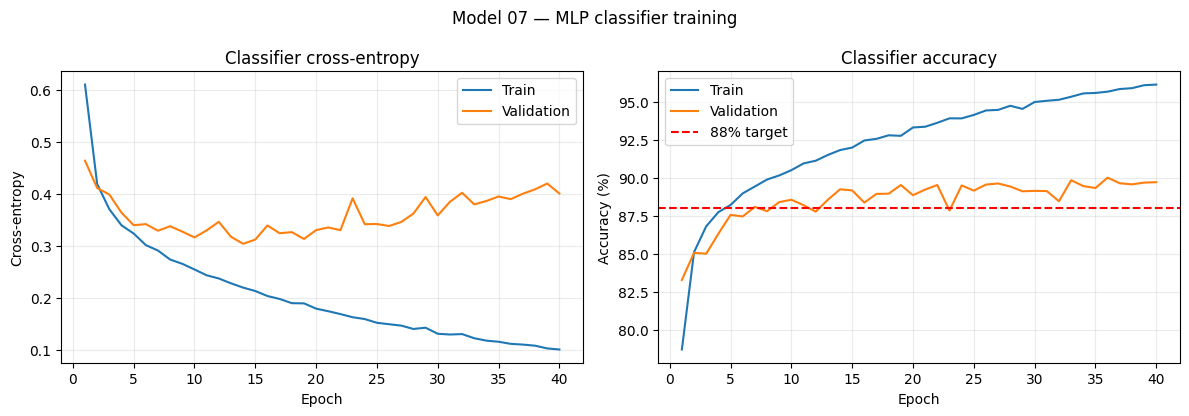

In [6]:
if not classifier_history:
    with open(CLASSIFIER_HISTORY_PATH, "r") as f:
        classifier_history = [
            {k: (int(v) if k == "epoch" else float(v) if k not in {"is_best"} else v == "True")
             for k, v in row.items()}
            for row in csv.DictReader(f)
        ]

epochs_plot = [r["epoch"] for r in classifier_history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(epochs_plot, [r["train_cross_entropy"] for r in classifier_history], label="Train")
axes[0].plot(epochs_plot, [r["val_cross_entropy"] for r in classifier_history], label="Validation")
axes[0].set_title("Classifier cross-entropy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(epochs_plot, [100*r["train_accuracy"] for r in classifier_history], label="Train")
axes[1].plot(epochs_plot, [100*r["val_accuracy"] for r in classifier_history], label="Validation")
axes[1].axhline(100*CLASSIFIER_TARGET_TEST_ACCURACY, color="red", linestyle="--", label="88% target")
axes[1].set_title("Classifier accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.suptitle("Model 07 — MLP classifier training")
fig.tight_layout()
fig.savefig(FIG_CLASSIFIER_CURVES, dpi=220, bbox_inches="tight")
plt.show()

Best checkpoint epoch : 36
Test accuracy         : 89.8571%
Test cross-entropy    : 0.377755
88% target met        : True


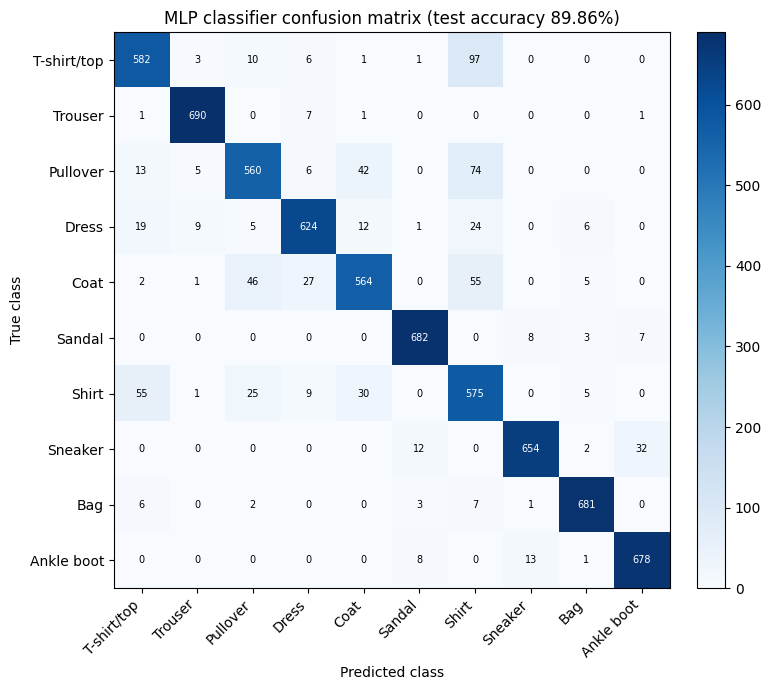

Saved latent features: /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier/results/features/mlp_latent_features.npz
Saved W1/W2/W3 and biases: /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier/results/classifier_weights.npz


In [7]:
for parameter in classifier.parameters():
    parameter.requires_grad_(False)
classifier.eval()

def collect_classifier_outputs(model, loader):
    model.eval()
    latent_parts, logits_parts, image_parts, label_parts = [], [], [], []
    with torch.inference_mode():
        for images, targets in loader:
            images_device = images.to(DEVICE, non_blocking=True)
            logits, z = model(images_device)
            latent_parts.append(z.cpu())
            logits_parts.append(logits.cpu())
            image_parts.append(images.cpu())
            label_parts.append(targets.cpu())
    return (
        torch.cat(latent_parts, dim=0),
        torch.cat(logits_parts, dim=0),
        torch.cat(image_parts, dim=0),
        torch.cat(label_parts, dim=0),
    )

train_feature_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
val_feature_loader = DataLoader(
    val_set, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
test_feature_loader = DataLoader(
    test_set, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)

z_train_t, logits_train_t, images_train_t, y_train_t = collect_classifier_outputs(classifier, train_feature_loader)
z_val_t, logits_val_t, images_val_t, y_val_t = collect_classifier_outputs(classifier, val_feature_loader)
z_test_t, logits_test_t, images_test_t, y_test_t = collect_classifier_outputs(classifier, test_feature_loader)

test_predictions = logits_test_t.argmax(dim=1)
test_accuracy = float((test_predictions == y_test_t).float().mean().item())
test_cross_entropy = float(F.cross_entropy(logits_test_t, y_test_t).item())
test_target_met = bool(test_accuracy >= CLASSIFIER_TARGET_TEST_ACCURACY)

confusion_matrix = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64)
for true_label, predicted_label in zip(y_test_t.tolist(), test_predictions.tolist()):
    confusion_matrix[true_label, predicted_label] += 1

per_class_accuracy = {}
for class_id, class_name in enumerate(CLASS_NAMES):
    denom = int(confusion_matrix[class_id].sum().item())
    per_class_accuracy[class_name] = (
        float(confusion_matrix[class_id, class_id].item() / denom) if denom else None
    )

print(f"Best checkpoint epoch : {best_classifier_checkpoint['best_epoch']}")
print(f"Test accuracy         : {test_accuracy:.4%}")
print(f"Test cross-entropy    : {test_cross_entropy:.6f}")
print(f"88% target met        : {test_target_met}")
if not test_target_met:
    print("WARNING: The assignment's >=88% test-accuracy target has not been met. Review the classifier training before submission.")

cm = confusion_matrix.numpy()
fig, ax = plt.subplots(figsize=(8.2, 7.0))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"MLP classifier confusion matrix (test accuracy {test_accuracy:.2%})")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max()*0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIG_CONFUSION_MATRIX, dpi=220, bbox_inches="tight")
plt.show()

z_train = z_train_t.numpy().astype(np.float32)
z_val = z_val_t.numpy().astype(np.float32)
z_test = z_test_t.numpy().astype(np.float32)
y_train = y_train_t.numpy().astype(np.int64)
y_val = y_val_t.numpy().astype(np.int64)
y_test = y_test_t.numpy().astype(np.int64)
images_train = images_train_t.numpy().astype(np.float32)
images_val = images_val_t.numpy().astype(np.float32)
images_test = images_test_t.numpy().astype(np.float32)

np.savez_compressed(
    LATENT_FEATURES_PATH,
    z_train=z_train, y_train=y_train,
    z_validation=z_val, y_validation=y_val,
    z_test=z_test, y_test=y_test,
    train_indices=train_indices, validation_indices=val_indices, test_indices=test_indices,
)

W1 = classifier.fc1.weight.detach().cpu().numpy().astype(np.float32)
W2 = classifier.fc2.weight.detach().cpu().numpy().astype(np.float32)
W3 = classifier.fc3.weight.detach().cpu().numpy().astype(np.float32)
b1 = classifier.fc1.bias.detach().cpu().numpy().astype(np.float32)
b2 = classifier.fc2.bias.detach().cpu().numpy().astype(np.float32)
b3 = classifier.fc3.bias.detach().cpu().numpy().astype(np.float32)

np.savez_compressed(
    CLASSIFIER_WEIGHTS_PATH,
    W1=W1, W2=W2, W3=W3,
    b1=b1, b2=b2, b3=b3,
    W1_shape=np.asarray(W1.shape), W2_shape=np.asarray(W2.shape), W3_shape=np.asarray(W3.shape),
)
print("Saved latent features:", LATENT_FEATURES_PATH)
print("Saved W1/W2/W3 and biases:", CLASSIFIER_WEIGHTS_PATH)

In [8]:
classifier.eval()
for parameter in classifier.parameters():
    parameter.requires_grad_(False)
assert all(not p.requires_grad for p in classifier.parameters())

with torch.inference_mode():
    one_hot_classes = torch.eye(NUM_CLASSES, dtype=torch.float32, device=DEVICE)

    z_from_class = F.relu(one_hot_classes @ classifier.fc3.weight)
    h1_from_class = F.relu(z_from_class @ classifier.fc2.weight)
    class_weight_projections = torch.sigmoid(h1_from_class @ classifier.fc1.weight)
    class_weight_projections = class_weight_projections.view(NUM_CLASSES, 1, 28, 28)

    z_test_device = torch.from_numpy(z_test).to(DEVICE)
    h1_from_test_z = F.relu(z_test_device @ classifier.fc2.weight)
    latent_transpose_projections = torch.sigmoid(h1_from_test_z @ classifier.fc1.weight)
    latent_transpose_projections = latent_transpose_projections.view(-1, 1, 28, 28)

assert class_weight_projections.shape == (10, 1, 28, 28)
assert latent_transpose_projections.shape == (7000, 1, 28, 28)
assert torch.isfinite(class_weight_projections).all()
assert torch.isfinite(latent_transpose_projections).all()
assert float(class_weight_projections.min()) >= 0 and float(class_weight_projections.max()) <= 1
assert float(latent_transpose_projections.min()) >= 0 and float(latent_transpose_projections.max()) <= 1

class_weight_np = class_weight_projections.cpu().numpy()
latent_transpose_np = latent_transpose_projections.cpu().numpy()
np.savez_compressed(
    TRANSPOSE_RESULTS_PATH,
    class_onehot=np.eye(NUM_CLASSES, dtype=np.float32),
    class_weight_projections=class_weight_np,
    latent_transpose_projections=latent_transpose_np,
)

def orthogonality_deviation(weight):
    w = weight.detach().double().cpu()
    gram = w.T @ w
    identity = torch.eye(gram.shape[0], dtype=gram.dtype)
    return float(torch.linalg.norm(gram - identity, ord="fro") / torch.linalg.norm(identity, ord="fro"))

orthogonality_diagnostics = {
    "W1_transpose_W1_relative_frobenius_deviation_from_identity": orthogonality_deviation(classifier.fc1.weight),
    "W2_transpose_W2_relative_frobenius_deviation_from_identity": orthogonality_deviation(classifier.fc2.weight),
    "W3_transpose_W3_relative_frobenius_deviation_from_identity": orthogonality_deviation(classifier.fc3.weight),
}

neg1_total = 0
neg2_total = 0
element_total_1 = 0
element_total_2 = 0
with torch.inference_mode():
    for images, _ in test_feature_loader:
        x = images.to(DEVICE).view(images.size(0), -1)
        a1 = classifier.fc1(x)
        h1 = F.relu(a1)
        a2 = classifier.fc2(h1)
        neg1_total += int((a1 < 0).sum().item())
        neg2_total += int((a2 < 0).sum().item())
        element_total_1 += a1.numel()
        element_total_2 += a2.numel()

relu_diagnostics = {
    "hidden1_negative_preactivation_fraction": neg1_total / element_total_1,
    "hidden2_negative_preactivation_fraction": neg2_total / element_total_2,
}

print("W1 stored shape:", tuple(classifier.fc1.weight.shape), "forward map 784 -> 256")
print("W2 stored shape:", tuple(classifier.fc2.weight.shape), "forward map 256 -> 64")
print("W3 stored shape:", tuple(classifier.fc3.weight.shape), "forward map 64 -> 10")
print("Transpose-only class projections:", tuple(class_weight_projections.shape))
print("Transpose-only test latent projections:", tuple(latent_transpose_projections.shape))
print("Orthogonality diagnostics:", orthogonality_diagnostics)
print("ReLU information-loss diagnostics:", relu_diagnostics)

W1 stored shape: (256, 784) forward map 784 -> 256
W2 stored shape: (64, 256) forward map 256 -> 64
W3 stored shape: (10, 64) forward map 64 -> 10
Transpose-only class projections: (10, 1, 28, 28)
Transpose-only test latent projections: (7000, 1, 28, 28)
Orthogonality diagnostics: {'W1_transpose_W1_relative_frobenius_deviation_from_identity': 25.40884860246649, 'W2_transpose_W2_relative_frobenius_deviation_from_identity': 5.745400895734073, 'W3_transpose_W3_relative_frobenius_deviation_from_identity': 2.636826441044219}
ReLU information-loss diagnostics: {'hidden1_negative_preactivation_fraction': 0.7476690848214286, 'hidden2_negative_preactivation_fraction': 0.5428638392857142}


In [9]:
class FrozenLatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc2 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def forward(self, z):
        x = F.relu(self.fc1(z))
        x = torch.sigmoid(self.fc2(x))
        return x.view(-1, 1, 28, 28)


seed_everything(SEED + 700)
decoder = FrozenLatentDecoder().to(DEVICE)
decoder_params = sum(p.numel() for p in decoder.parameters() if p.requires_grad)
assert decoder_params == 218128, decoder_params

with torch.inference_mode():
    smoke_z = torch.randn(4, LATENT_DIM, device=DEVICE)
    smoke_recon = decoder(smoke_z)
assert smoke_recon.shape == (4, 1, 28, 28)
assert torch.isfinite(smoke_recon).all()
assert float(smoke_recon.min()) >= 0 and float(smoke_recon.max()) <= 1
print(decoder)
print(f"Frozen latent decoder trainable parameters: {decoder_params:,}")

FrozenLatentDecoder(
  (fc1): Linear(in_features=64, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=784, bias=True)
)
Frozen latent decoder trainable parameters: 218,128


In [10]:
DECODER_CONFIG = {
    "model_name": "07_frozen_mlp_latent_decoder",
    "architecture": "64 -> 256 -> 784",
    "hidden_activation": "ReLU",
    "output_activation": "Sigmoid",
    "input_features": "64-dimensional post-ReLU latent features from frozen trained MLP classifier",
    "classifier_frozen": True,
    "loss": "MSELoss(reduction='mean')",
    "optimizer": "Adam",
    "learning_rate": DECODER_LR,
    "batch_size": BATCH_SIZE,
    "epochs": DECODER_EPOCHS,
    "seed": SEED + 700,
    "best_checkpoint_selection": "lowest validation reconstruction MSE",
    "trainable_parameters": decoder_params,
}

DECODER_RELATED_OUTPUTS = [
    DECODER_BEST_PATH, DECODER_LAST_PATH, DECODER_HISTORY_PATH,
    LATENT_STATS_PATH, FIG_DECODER_COMPARISON, FIG_GAUSSIAN_SAMPLES, FIG_SUMMARY,
]
run_mode_prepare(
    DECODER_RUN_MODE, DECODER_RELATED_OUTPUTS,
    DECODER_LAST_PATH, "Frozen decoder",
)

decoder_train_dataset = TensorDataset(
    torch.from_numpy(z_train).float(),
    torch.from_numpy(images_train.reshape(-1, INPUT_DIM)).float(),
)
decoder_val_dataset = TensorDataset(
    torch.from_numpy(z_val).float(),
    torch.from_numpy(images_val.reshape(-1, INPUT_DIM)).float(),
)
decoder_test_dataset = TensorDataset(
    torch.from_numpy(z_test).float(),
    torch.from_numpy(images_test.reshape(-1, INPUT_DIM)).float(),
)

decoder_loader_generator = torch.Generator(device="cpu")
decoder_loader_generator.manual_seed(SEED + 700)

decoder_train_loader = DataLoader(
    decoder_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=decoder_loader_generator, num_workers=0, pin_memory=PIN_MEMORY,
)
decoder_val_loader = DataLoader(
    decoder_val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=PIN_MEMORY,
)

decoder_optimizer = torch.optim.Adam(decoder.parameters(), lr=DECODER_LR)

def evaluate_decoder_loss(model, loader):
    model.eval()
    squared_error_sum = 0.0
    total_pixels = 0
    with torch.inference_mode():
        for z_batch, target_flat in loader:
            z_batch = z_batch.to(DEVICE, non_blocking=True)
            target_flat = target_flat.to(DEVICE, non_blocking=True)
            recon = model(z_batch).view(-1, INPUT_DIM)
            squared_error_sum += (recon.double() - target_flat.double()).pow(2).sum().item()
            total_pixels += target_flat.numel()
    return squared_error_sum / total_pixels

def decoder_checkpoint_payload(epoch, history, best_val_mse):
    return {
        "epoch": int(epoch),
        "model_state_dict": decoder.state_dict(),
        "optimizer_state_dict": decoder_optimizer.state_dict(),
        "history": history,
        "best_val_mse": float(best_val_mse),
        "config": DECODER_CONFIG,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all() if USE_CUDA else [],
        "loader_generator_state": decoder_loader_generator.get_state(),
        "split_hashes": SPLIT_HASHES,
    }

decoder_history = []
best_decoder_val_mse = float("inf")
decoder_start_epoch = 1

if DECODER_RUN_MODE == "resume":
    decoder_ckpt = torch.load(DECODER_LAST_PATH, map_location=DEVICE, weights_only=True)
    assert decoder_ckpt["split_hashes"] == SPLIT_HASHES
    assert decoder_ckpt["config"] == DECODER_CONFIG
    decoder.load_state_dict(decoder_ckpt["model_state_dict"], strict=True)
    decoder_optimizer.load_state_dict(decoder_ckpt["optimizer_state_dict"])
    decoder_history = decoder_ckpt["history"]
    best_decoder_val_mse = float(decoder_ckpt["best_val_mse"])
    decoder_start_epoch = int(decoder_ckpt["epoch"]) + 1
    decoder_loader_generator.set_state(decoder_ckpt["loader_generator_state"].cpu())
    torch.set_rng_state(decoder_ckpt["torch_rng_state"].cpu())
    if USE_CUDA and decoder_ckpt["cuda_rng_states"]:
        torch.cuda.set_rng_state_all(decoder_ckpt["cuda_rng_states"])
    print(f"Resuming frozen decoder from epoch {decoder_start_epoch}.")
else:
    print("Starting a fresh frozen-latent decoder run.")

decoder_training_start = time.perf_counter()
for epoch in range(decoder_start_epoch, DECODER_EPOCHS + 1):
    decoder.train()
    if USE_CUDA:
        torch.cuda.synchronize()
    epoch_start = time.perf_counter()

    train_sse = 0.0
    train_pixels = 0
    for z_batch, target_flat in decoder_train_loader:
        z_batch = z_batch.to(DEVICE, non_blocking=True)
        target_flat = target_flat.to(DEVICE, non_blocking=True)

        decoder_optimizer.zero_grad(set_to_none=True)
        recon_flat = decoder(z_batch).view(-1, INPUT_DIM)
        loss = F.mse_loss(recon_flat, target_flat, reduction="mean")
        loss.backward()
        decoder_optimizer.step()

        train_sse += (recon_flat.detach().double() - target_flat.double()).pow(2).sum().item()
        train_pixels += target_flat.numel()

    if USE_CUDA:
        torch.cuda.synchronize()
    train_mse = train_sse / train_pixels
    val_mse = evaluate_decoder_loss(decoder, decoder_val_loader)

    is_best = val_mse < best_decoder_val_mse
    if is_best:
        best_decoder_val_mse = float(val_mse)
        atomic_torch_save({
            "model_name": "07_frozen_mlp_latent_decoder",
            "model_state_dict": decoder.state_dict(),
            "best_epoch": epoch,
            "best_val_mse": best_decoder_val_mse,
            "trainable_params": decoder_params,
            "config": DECODER_CONFIG,
            "split_hashes": SPLIT_HASHES,
        }, DECODER_BEST_PATH)

    epoch_wall_time_s = time.perf_counter() - epoch_start
    decoder_history.append({
        "epoch": int(epoch),
        "train_mse": float(train_mse),
        "val_mse": float(val_mse),
        "epoch_wall_time_s": float(epoch_wall_time_s),
        "is_best": bool(is_best),
    })

    atomic_torch_save(
        decoder_checkpoint_payload(epoch, decoder_history, best_decoder_val_mse),
        DECODER_LAST_PATH,
    )
    write_history_csv(decoder_history, DECODER_HISTORY_PATH)

    print(
        f"Decoder epoch {epoch:02d}/{DECODER_EPOCHS} | "
        f"train MSE {train_mse:.6f} | val MSE {val_mse:.6f} | "
        f"{epoch_wall_time_s:.1f}s"
        + (" | BEST" if is_best else "")
    )

decoder_training_session_wall_time_s = time.perf_counter() - decoder_training_start
decoder_training_total_s = float(sum(row["epoch_wall_time_s"] for row in decoder_history))
assert DECODER_BEST_PATH.is_file()
best_decoder_checkpoint = torch.load(DECODER_BEST_PATH, map_location=DEVICE, weights_only=True)
decoder.load_state_dict(best_decoder_checkpoint["model_state_dict"], strict=True)
decoder.eval()

print(f"Frozen decoder best epoch: {best_decoder_checkpoint['best_epoch']}")
print(f"Best validation MSE: {best_decoder_checkpoint['best_val_mse']:.8f}")

Starting a fresh frozen-latent decoder run.
Decoder epoch 01/30 | train MSE 0.035204 | val MSE 0.025820 | 1.4s | BEST
Decoder epoch 02/30 | train MSE 0.024521 | val MSE 0.022837 | 1.2s | BEST
Decoder epoch 03/30 | train MSE 0.022425 | val MSE 0.021456 | 1.2s | BEST
Decoder epoch 04/30 | train MSE 0.021299 | val MSE 0.020715 | 1.2s | BEST
Decoder epoch 05/30 | train MSE 0.020587 | val MSE 0.020095 | 1.3s | BEST
Decoder epoch 06/30 | train MSE 0.020052 | val MSE 0.020036 | 1.5s | BEST
Decoder epoch 07/30 | train MSE 0.019638 | val MSE 0.019451 | 1.5s | BEST
Decoder epoch 08/30 | train MSE 0.019334 | val MSE 0.019116 | 1.4s | BEST
Decoder epoch 09/30 | train MSE 0.019073 | val MSE 0.018990 | 1.2s | BEST
Decoder epoch 10/30 | train MSE 0.018875 | val MSE 0.018805 | 1.2s | BEST
Decoder epoch 11/30 | train MSE 0.018687 | val MSE 0.018618 | 1.2s | BEST
Decoder epoch 12/30 | train MSE 0.018507 | val MSE 0.018494 | 1.2s | BEST
Decoder epoch 13/30 | train MSE 0.018387 | val MSE 0.018383 | 1.2s |

In [11]:
def predict_decoder_from_latents(model, z_array, batch_size=512):
    model.eval()
    outputs = []
    with torch.inference_mode():
        for start in range(0, len(z_array), batch_size):
            z_batch = torch.from_numpy(z_array[start:start+batch_size]).float().to(DEVICE)
            outputs.append(model(z_batch).cpu())
    return torch.cat(outputs, dim=0).numpy().astype(np.float32)

frozen_decoder_test_recon = predict_decoder_from_latents(decoder, z_test)
test_images_np = images_test.astype(np.float32)

class VanillaAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM),
            nn.Sigmoid(),
        )

    def forward(self, images):
        latent = self.encoder(images)
        reconstruction = self.decoder(latent).view(-1, 1, 28, 28)
        return reconstruction, latent

assert MODEL01_BEST_PATH.is_file(), (
    "Model 01 best_model.pth is required for the same-latent-dimension comparison."
)
assert MODEL01_METRICS_PATH.is_file()
ae_checkpoint = torch.load(MODEL01_BEST_PATH, map_location="cpu", weights_only=True)
ae_reference_metrics = json.load(open(MODEL01_METRICS_PATH, "r"))
vanilla_ae = VanillaAutoencoder().to(DEVICE)
vanilla_ae.load_state_dict(ae_checkpoint["model_state_dict"], strict=True)
vanilla_ae.eval()

ae_recon_parts = []
with torch.inference_mode():
    for images, _ in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        reconstruction, _ = vanilla_ae(images)
        ae_recon_parts.append(reconstruction.cpu())
vanilla_ae_test_recon = torch.cat(ae_recon_parts, dim=0).numpy().astype(np.float32)

def compute_reconstruction_metrics(originals, reconstructions):
    originals = np.asarray(originals, dtype=np.float32)
    reconstructions = np.asarray(reconstructions, dtype=np.float32)
    assert originals.shape == reconstructions.shape == (7000, 1, 28, 28)

    squared_error_sum = float(
        np.square(originals.astype(np.float64) - reconstructions.astype(np.float64)).sum()
    )
    total_pixels = int(originals.size)
    mse = squared_error_sum / total_pixels
    psnr = float("inf") if mse == 0 else 10.0 * math.log10(1.0 / mse)

    ssim_values = [
        float(structural_similarity(orig.squeeze(0), recon.squeeze(0), **SSIM_PARAMS))
        for orig, recon in zip(originals, reconstructions)
    ]
    return {
        "num_images": int(len(originals)),
        "num_pixels": total_pixels,
        "mse": float(mse),
        "psnr_db": float(psnr),
        "ssim_mean": float(np.mean(ssim_values)),
        "ssim_std": float(np.std(ssim_values, ddof=1)),
        "ssim_count": int(len(ssim_values)),
        "ssim_params": SSIM_PARAMS,
    }

frozen_decoder_metrics = compute_reconstruction_metrics(test_images_np, frozen_decoder_test_recon)
vanilla_ae_metrics = compute_reconstruction_metrics(test_images_np, vanilla_ae_test_recon)

for metric_key, saved_key in [
    ("mse", "mse"), ("psnr_db", "psnr_db"), ("ssim_mean", "ssim_mean")
]:
    saved_value = ae_reference_metrics["test"][saved_key]
    current_value = vanilla_ae_metrics[metric_key]
    assert math.isclose(float(saved_value), float(current_value), rel_tol=1e-5, abs_tol=1e-7), (
        f"Model 01 reference mismatch for {metric_key}: saved={saved_value}, recomputed={current_value}"
    )

print("Reconstruction comparison (same test set):")
print("Vanilla AE (Model 01):", vanilla_ae_metrics)
print("Frozen MLP decoder   :", frozen_decoder_metrics)

Reconstruction comparison (same test set):
Vanilla AE (Model 01): {'num_images': 7000, 'num_pixels': 5488000, 'mse': 0.008072855411403672, 'psnr_db': 20.929728258631535, 'ssim_mean': 0.7451858474965833, 'ssim_std': 0.14759616140535184, 'ssim_count': 7000, 'ssim_params': {'data_range': 1.0, 'gaussian_weights': True, 'sigma': 1.5, 'win_size': 11, 'use_sample_covariance': False}}
Frozen MLP decoder   : {'num_images': 7000, 'num_pixels': 5488000, 'mse': 0.018037717748610863, 'psnr_db': 17.43818413129255, 'ssim_mean': 0.5962330031760656, 'ssim_std': 0.18359208841613908, 'ssim_count': 7000, 'ssim_params': {'data_range': 1.0, 'gaussian_weights': True, 'sigma': 1.5, 'win_size': 11, 'use_sample_covariance': False}}


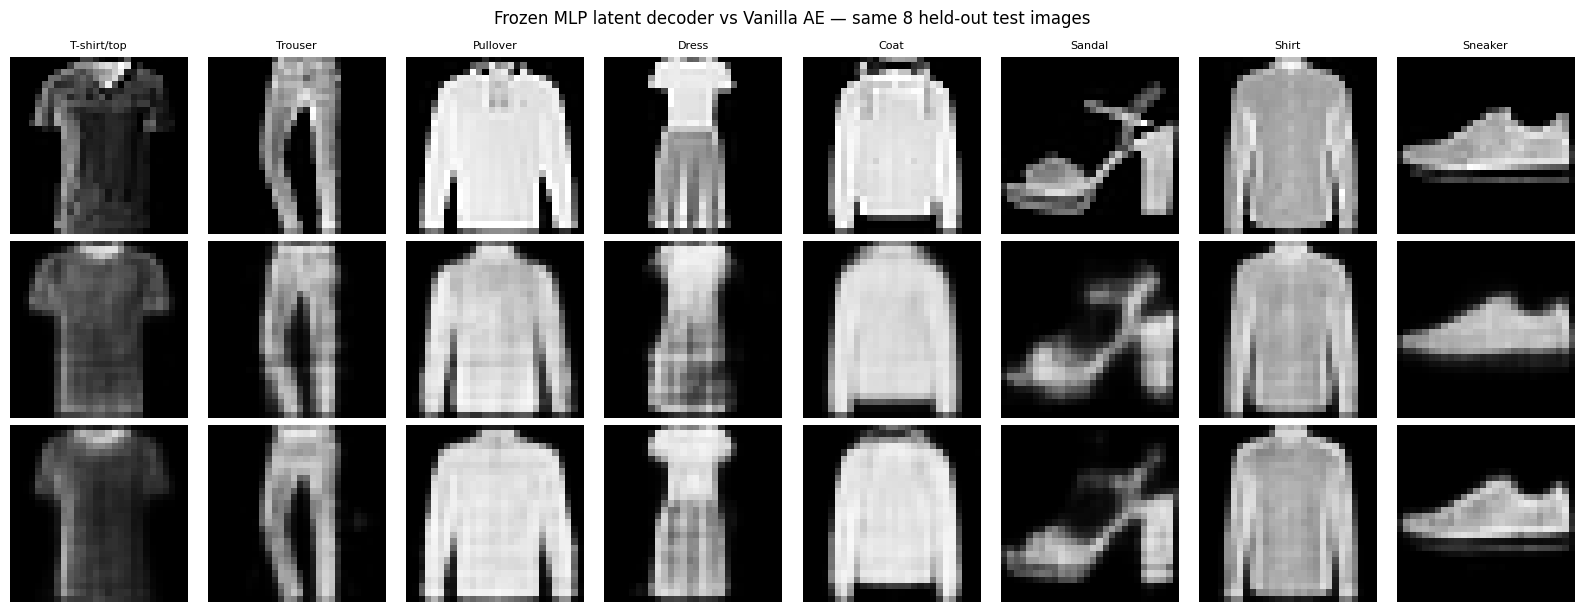

In [12]:
first_test_position_by_class = {}
for position, label in enumerate(y_test.tolist()):
    if label not in first_test_position_by_class:
        first_test_position_by_class[label] = position
    if len(first_test_position_by_class) == NUM_CLASSES:
        break

selected_positions = [first_test_position_by_class[c] for c in range(8)]
assert len(selected_positions) == 8

fig, axes = plt.subplots(3, 8, figsize=(16, 6.2))
row_names = ["Original", "Frozen MLP decoder", "Vanilla AE"]
for col, position in enumerate(selected_positions):
    axes[0, col].imshow(test_images_np[position, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, col].imshow(frozen_decoder_test_recon[position, 0], cmap="gray", vmin=0, vmax=1)
    axes[2, col].imshow(vanilla_ae_test_recon[position, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(CLASS_NAMES[int(y_test[position])], fontsize=8)
for row in range(3):
    axes[row, 0].set_ylabel(row_names[row], fontsize=9)
    for col in range(8):
        axes[row, col].axis("off")
fig.suptitle("Frozen MLP latent decoder vs Vanilla AE — same 8 held-out test images")
fig.tight_layout()
fig.savefig(FIG_DECODER_COMPARISON, dpi=240, bbox_inches="tight")
plt.show()

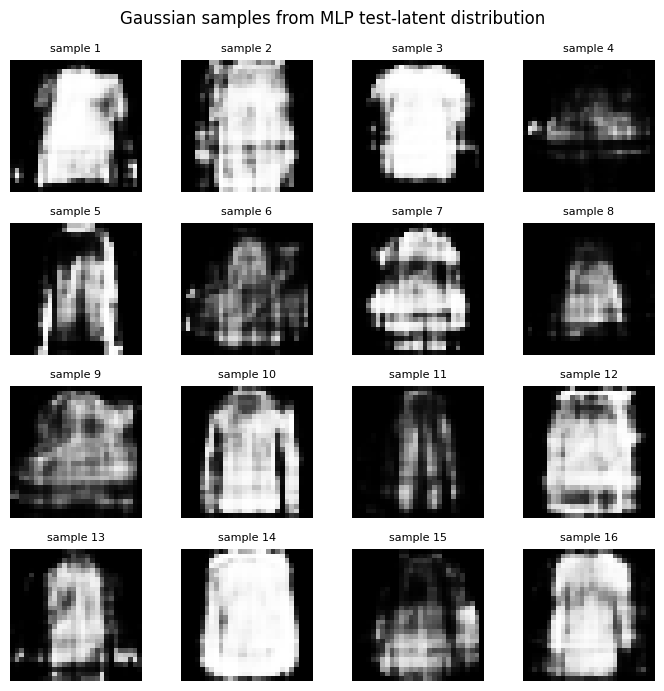

In [13]:
latent_mean = z_test.mean(axis=0).astype(np.float32)
latent_std = z_test.std(axis=0, ddof=0).astype(np.float32)
latent_std_safe = np.maximum(latent_std, 1e-6)

LATENT_SAMPLE_SEED = 7042
latent_sample_generator = torch.Generator(device="cpu")
latent_sample_generator.manual_seed(LATENT_SAMPLE_SEED)

eps = torch.randn((16, LATENT_DIM), generator=latent_sample_generator)
sampled_z = torch.from_numpy(latent_mean).unsqueeze(0) + eps * torch.from_numpy(latent_std_safe).unsqueeze(0)

with torch.inference_mode():
    gaussian_latent_samples = decoder(sampled_z.to(DEVICE)).cpu().numpy().astype(np.float32)

assert gaussian_latent_samples.shape == (16, 1, 28, 28)
assert np.isfinite(gaussian_latent_samples).all()
assert gaussian_latent_samples.min() >= 0 and gaussian_latent_samples.max() <= 1

np.savez_compressed(
    LATENT_STATS_PATH,
    mean=latent_mean,
    std_population=latent_std,
    std_used=latent_std_safe,
    sample_z=sampled_z.numpy(),
    seed=np.asarray(LATENT_SAMPLE_SEED),
)

fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(gaussian_latent_samples[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"sample {i+1}", fontsize=8)
    ax.axis("off")
fig.suptitle("Gaussian samples from MLP test-latent distribution")
fig.tight_layout()
fig.savefig(FIG_GAUSSIAN_SAMPLES, dpi=240, bbox_inches="tight")
plt.show()

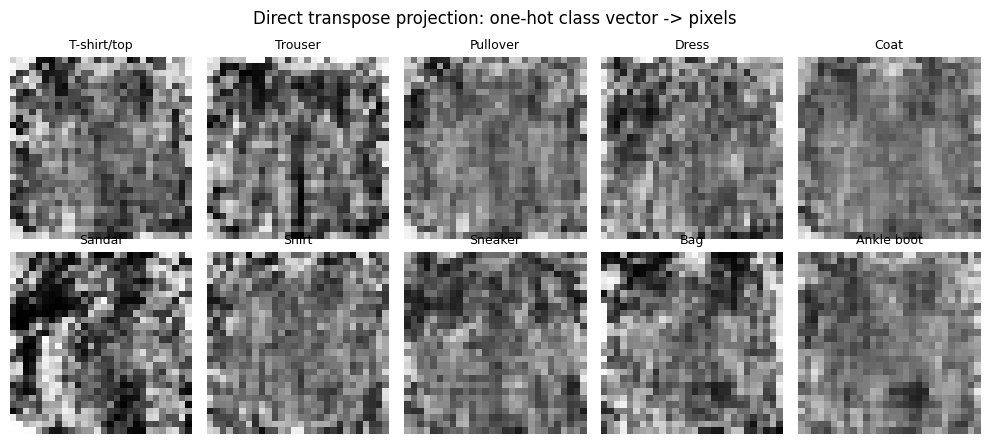

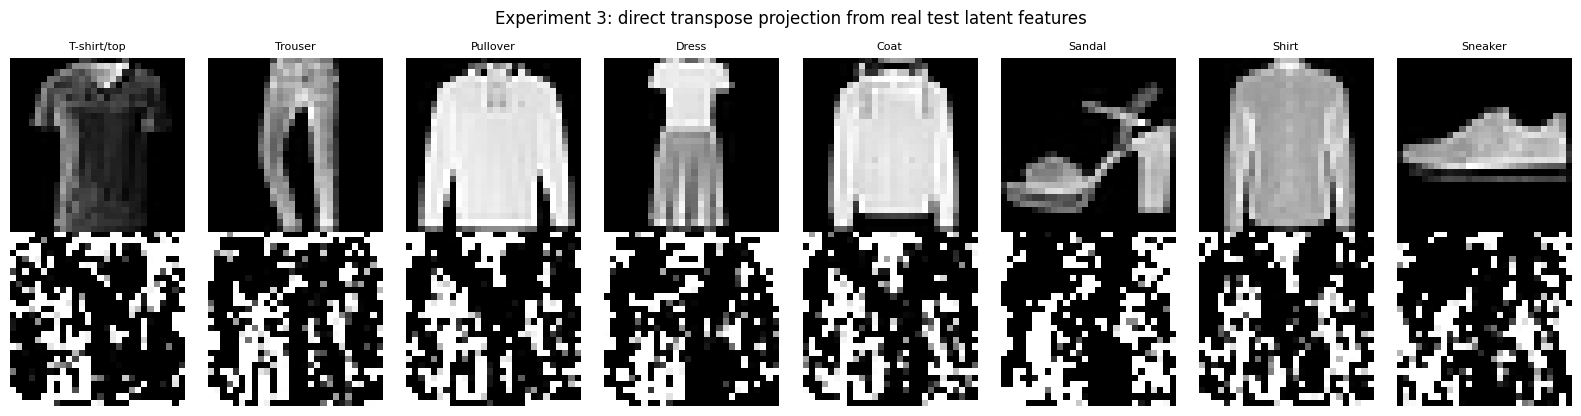

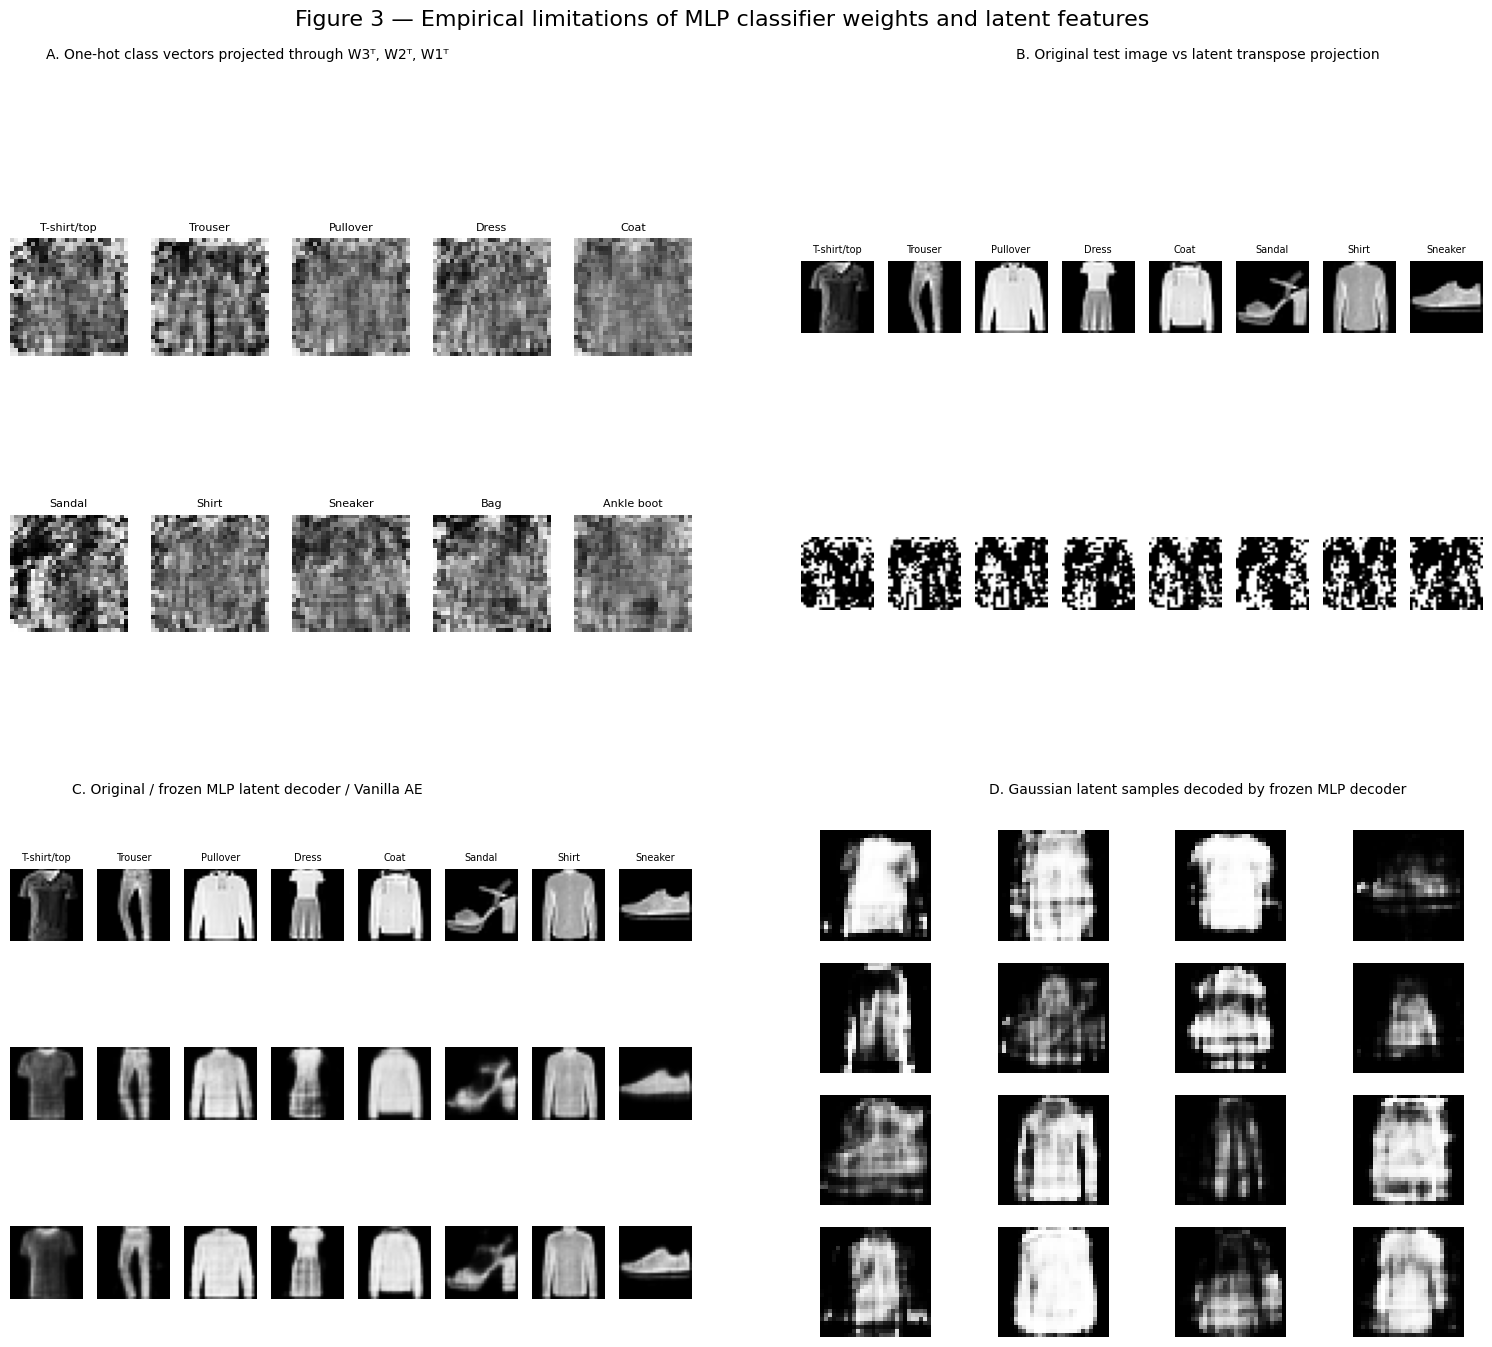

Saved combined Figure 3: /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier/results/figures/figure3_mlp_classifier_limitations.png


In [14]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for class_id, ax in enumerate(axes.flat):
    ax.imshow(class_weight_np[class_id, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[class_id], fontsize=9)
    ax.axis("off")
fig.suptitle("Direct transpose projection: one-hot class vector -> pixels")
fig.tight_layout()
fig.savefig(FIG_CLASS_WEIGHT_PROJECTION, dpi=240, bbox_inches="tight")
plt.show()

latent_projection_samples = latent_transpose_np[selected_positions]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.2))
for col, position in enumerate(selected_positions):
    axes[0, col].imshow(test_images_np[position, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, col].imshow(latent_projection_samples[col, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(CLASS_NAMES[int(y_test[position])], fontsize=8)
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].set_ylabel("Original", fontsize=9)
axes[1, 0].set_ylabel("Transpose projection", fontsize=9)
fig.suptitle("Experiment 3: direct transpose projection from real test latent features")
fig.tight_layout()
fig.savefig(FIG_LATENT_TRANSPOSE, dpi=240, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(19, 15))
outer = fig.add_gridspec(2, 2, wspace=0.16, hspace=0.28)

gs_a = outer[0, 0].subgridspec(2, 5)
for i in range(10):
    ax = fig.add_subplot(gs_a[i // 5, i % 5])
    ax.imshow(class_weight_np[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[i], fontsize=8)
    ax.axis("off")
fig.text(0.25, 0.965, "A. One-hot class vectors projected through W3ᵀ, W2ᵀ, W1ᵀ",
         ha="center", va="center", fontsize=10)

gs_b = outer[0, 1].subgridspec(2, 8)
for col, position in enumerate(selected_positions):
    ax1 = fig.add_subplot(gs_b[0, col])
    ax1.imshow(test_images_np[position, 0], cmap="gray", vmin=0, vmax=1)
    ax1.set_title(CLASS_NAMES[int(y_test[position])], fontsize=7)
    ax1.axis("off")
    ax2 = fig.add_subplot(gs_b[1, col])
    ax2.imshow(latent_projection_samples[col, 0], cmap="gray", vmin=0, vmax=1)
    ax2.axis("off")
fig.text(0.75, 0.965, "B. Original test image vs latent transpose projection",
         ha="center", va="center", fontsize=10)

gs_c = outer[1, 0].subgridspec(3, 8)
for col, position in enumerate(selected_positions):
    for row, arr in enumerate([
        test_images_np[position, 0],
        frozen_decoder_test_recon[position, 0],
        vanilla_ae_test_recon[position, 0],
    ]):
        ax = fig.add_subplot(gs_c[row, col])
        ax.imshow(arr, cmap="gray", vmin=0, vmax=1)
        if row == 0:
            ax.set_title(CLASS_NAMES[int(y_test[position])], fontsize=7)
        ax.axis("off")
fig.text(0.25, 0.475, "C. Original / frozen MLP latent decoder / Vanilla AE",
         ha="center", va="center", fontsize=10)

gs_d = outer[1, 1].subgridspec(4, 4)
for i in range(16):
    ax = fig.add_subplot(gs_d[i // 4, i % 4])
    ax.imshow(gaussian_latent_samples[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.text(0.75, 0.475, "D. Gaussian latent samples decoded by frozen MLP decoder",
         ha="center", va="center", fontsize=10)

fig.suptitle("Figure 3 — Empirical limitations of MLP classifier weights and latent features", fontsize=16, y=0.995)
fig.savefig(FIG_SUMMARY, dpi=260, bbox_inches="tight")
plt.show()
print("Saved combined Figure 3:", FIG_SUMMARY)

In [15]:
def synchronize_device():
    if USE_CUDA:
        torch.cuda.synchronize()

def measure_batch_latency(callable_fn, warmup_runs=LATENCY_WARMUP_RUNS, timed_runs=LATENCY_TIMED_RUNS):
    with torch.inference_mode():
        for _ in range(warmup_runs):
            callable_fn()
        synchronize_device()

        values = []
        for _ in range(timed_runs):
            synchronize_device()
            start = time.perf_counter()
            callable_fn()
            synchronize_device()
            values.append((time.perf_counter() - start) * 1000.0)
    values = np.asarray(values, dtype=np.float64)
    return {
        "mean_ms_per_batch": float(values.mean()),
        "std_ms_per_batch": float(values.std(ddof=1)),
        "median_ms_per_batch": float(np.median(values)),
        "min_ms_per_batch": float(values.min()),
        "max_ms_per_batch": float(values.max()),
        "ms_per_image": float(values.mean() / LATENCY_BATCH_SIZE),
        "batch_size": LATENCY_BATCH_SIZE,
        "warmup_runs": warmup_runs,
        "timed_runs": timed_runs,
        "device": str(DEVICE),
        "hardware": torch.cuda.get_device_name(0) if USE_CUDA else (platform.processor() or platform.machine()),
    }

latency_images = torch.from_numpy(images_test[:LATENCY_BATCH_SIZE]).to(DEVICE)
latency_latents = torch.from_numpy(z_test[:LATENCY_BATCH_SIZE]).to(DEVICE)

classifier.eval()
decoder.eval()
classifier_latency = measure_batch_latency(lambda: classifier(latency_images))
decoder_latency = measure_batch_latency(lambda: decoder(latency_latents))

print("Classifier latency:", classifier_latency)
print("Frozen decoder latency:", decoder_latency)

Classifier latency: {'mean_ms_per_batch': 0.25027329000408827, 'std_ms_per_batch': 0.20287101204170954, 'median_ms_per_batch': 0.207240500003536, 'min_ms_per_batch': 0.16084499998214596, 'max_ms_per_batch': 2.162976000022354, 'ms_per_image': 0.003910520156313879, 'batch_size': 64, 'warmup_runs': 20, 'timed_runs': 100, 'device': 'cuda', 'hardware': 'Tesla T4'}
Frozen decoder latency: {'mean_ms_per_batch': 0.16140359000814897, 'std_ms_per_batch': 0.05201362330950986, 'median_ms_per_batch': 0.14145899996265143, 'min_ms_per_batch': 0.1092610000341665, 'max_ms_per_batch': 0.37650800004485063, 'ms_per_image': 0.0025219310938773276, 'batch_size': 64, 'warmup_runs': 20, 'timed_runs': 100, 'device': 'cuda', 'hardware': 'Tesla T4'}


In [16]:
def finite_json_value(value):
    if isinstance(value, (np.floating, float)):
        value = float(value)
        if not math.isfinite(value):
            raise ValueError(f"Non-finite value cannot be written to strict JSON: {value}")
        return value
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, dict):
        return {str(k): finite_json_value(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [finite_json_value(v) for v in value]
    return value

runtime_versions = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "scikit_image": skimage.__version__,
    "matplotlib": matplotlib.__version__,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if USE_CUDA else None,
    "device": str(DEVICE),
    "hardware": torch.cuda.get_device_name(0) if USE_CUDA else (platform.processor() or platform.machine()),
}

latent_transpose_metrics = compute_reconstruction_metrics(test_images_np, latent_transpose_np)

metrics = {
    "model_name": "07_mlp_classifier_limitation_experiments",
    "seed": SEED,
    "dataset": {
        "name": "Fashion-MNIST",
        "pooled_images": 70000,
        "split_counts": split_report["split_counts"],
        "split_per_class_counts": split_report["per_class_counts"],
        "split_sha256_int64": SPLIT_HASHES,
        "original_official_test_partition_retained": False,
    },
    "classifier": {
        "architecture": "784 -> 256 -> 64 -> 10",
        "trainable_params": classifier_params,
        "latent_dim": LATENT_DIM,
        "epochs_configured": CLASSIFIER_EPOCHS,
        "epochs_completed": len(classifier_history),
        "best_epoch": int(best_classifier_checkpoint["best_epoch"]),
        "best_val_accuracy": float(best_classifier_checkpoint["best_val_accuracy"]),
        "best_val_cross_entropy": float(best_classifier_checkpoint["best_val_cross_entropy"]),
        "test_accuracy": test_accuracy,
        "test_cross_entropy": test_cross_entropy,
        "target_test_accuracy": CLASSIFIER_TARGET_TEST_ACCURACY,
        "target_met": test_target_met,
        "per_class_test_accuracy": per_class_accuracy,
        "confusion_matrix": cm.tolist(),
        "loss": "CrossEntropyLoss on raw logits",
        "optimizer": "Adam",
        "learning_rate": CLASSIFIER_LR,
        "batch_size": BATCH_SIZE,
        "total_training_epoch_wall_time_s": float(classifier_training_total_s),
        "current_session_wall_time_s": float(classifier_training_session_wall_time_s),
    },
    "saved_classifier_weights": {
        "W1_shape_pytorch_out_in": list(W1.shape),
        "W2_shape_pytorch_out_in": list(W2.shape),
        "W3_shape_pytorch_out_in": list(W3.shape),
        "W1_forward_map": "784 -> 256; nn.Linear.weight shape [256,784]",
        "W2_forward_map": "256 -> 64; nn.Linear.weight shape [64,256]",
        "W3_forward_map": "64 -> 10; nn.Linear.weight shape [10,64]",
        "biases_saved_separately": True,
        "file": str(CLASSIFIER_WEIGHTS_PATH),
    },
    "latent_features": {
        "definition": "post-ReLU fc2 output immediately before fc3",
        "train_shape": list(z_train.shape),
        "validation_shape": list(z_val.shape),
        "test_shape": list(z_test.shape),
        "file": str(LATENT_FEATURES_PATH),
    },
    "transpose_projections": {
        "direct_onehot_to_pixels": {
            "num_classes": NUM_CLASSES,
            "output_shape": list(class_weight_np.shape),
            "formula_column_vector": "z_hat=ReLU(W3^T y_c); h1_hat=ReLU(W2^T z_hat); x_hat=Sigmoid(W1^T h1_hat)",
            "biases_used": False,
        },
        "real_test_latent_to_pixels": {
            "num_test_images": 7000,
            "output_shape": list(latent_transpose_np.shape),
            "formula_column_vector": "h1_hat=ReLU(W2^T z_MLP); x_hat=Sigmoid(W1^T h1_hat)",
            "biases_used": False,
            "diagnostic_reconstruction_metrics": latent_transpose_metrics,
        },
        "orthogonality_deviation": orthogonality_diagnostics,
        "relu_information_loss": relu_diagnostics,
    },
    "frozen_latent_decoder": {
        "architecture": "64 -> 256 -> 784",
        "trainable_params": decoder_params,
        "classifier_frozen": True,
        "training_epochs_configured": DECODER_EPOCHS,
        "epochs_completed": len(decoder_history),
        "best_epoch": int(best_decoder_checkpoint["best_epoch"]),
        "best_validation_mse": float(best_decoder_checkpoint["best_val_mse"]),
        "test_reconstruction_metrics": frozen_decoder_metrics,
        "total_epoch_wall_time_s": float(decoder_training_total_s),
        "current_session_wall_time_s": float(decoder_training_session_wall_time_s),
    },
    "vanilla_ae_reference": {
        "model": "Model 01 Vanilla Autoencoder, latent_dim=64",
        "checkpoint": str(MODEL01_BEST_PATH),
        "best_epoch": int(ae_checkpoint["best_epoch"]),
        "test_reconstruction_metrics_recomputed": vanilla_ae_metrics,
        "test_metrics_saved_by_model01": ae_reference_metrics["test"],
    },
    "experiment_5_gaussian_sampling": {
        "distribution": "z_rand ~ N(mu_z, diag(sigma_z^2))",
        "statistics_source": "MLP latent features from the 7,000-image test split, as specified by the assignment",
        "standard_deviation": "population standard deviation (ddof=0), with 1e-6 numerical floor",
        "seed": LATENT_SAMPLE_SEED,
        "num_samples": 16,
        "figure": str(FIG_GAUSSIAN_SAMPLES),
        "statistics_file": str(LATENT_STATS_PATH),
        "qualitative_only": True,
    },
    "inference_latency": {
        "classifier_forward": classifier_latency,
        "frozen_decoder_forward": decoder_latency,
    },
    "metric_applicability": {
        "classifier_accuracy": "classification metric for the MLP classifier",
        "frozen_decoder_mse_psnr_ssim": "reconstruction metrics for the separately trained frozen-latent decoder",
        "fid": "N/A; no MLP generative FID is required or computed",
    },
    "training_history": {
        "classifier_csv": str(CLASSIFIER_HISTORY_PATH),
        "decoder_csv": str(DECODER_HISTORY_PATH),
    },
    "artifacts": {
        "classifier_best_checkpoint": str(CLASSIFIER_BEST_PATH),
        "classifier_last_checkpoint": str(CLASSIFIER_LAST_PATH),
        "decoder_best_checkpoint": str(DECODER_BEST_PATH),
        "decoder_last_checkpoint": str(DECODER_LAST_PATH),
        "classifier_weights": str(CLASSIFIER_WEIGHTS_PATH),
        "latent_features": str(LATENT_FEATURES_PATH),
        "transpose_results": str(TRANSPOSE_RESULTS_PATH),
        "latent_statistics": str(LATENT_STATS_PATH),
        "split_report": str(SPLIT_REPORT_PATH),
        "classifier_curves": str(FIG_CLASSIFIER_CURVES),
        "confusion_matrix": str(FIG_CONFUSION_MATRIX),
        "direct_class_weight_projection": str(FIG_CLASS_WEIGHT_PROJECTION),
        "test_latent_transpose_projection": str(FIG_LATENT_TRANSPOSE),
        "frozen_decoder_vs_vanilla_ae": str(FIG_DECODER_COMPARISON),
        "gaussian_latent_samples": str(FIG_GAUSSIAN_SAMPLES),
        "figure3_summary": str(FIG_SUMMARY),
    },
    "runtime_versions": runtime_versions,
}

metrics = finite_json_value(metrics)
config = {
    "classifier": CLASSIFIER_CONFIG,
    "frozen_latent_decoder": DECODER_CONFIG,
    "dataset": {
        "name": "Fashion-MNIST",
        "preprocessing": "ToTensor() only; grayscale [1,28,28], [0,1]",
        "split": "exact Model 01 ordered stratified 80/10/10 split; seed 42",
        "split_hashes": SPLIT_HASHES,
        "batch_size": BATCH_SIZE,
    },
    "ssim_params": SSIM_PARAMS,
    "run_modes": {
        "classifier": CLASSIFIER_RUN_MODE,
        "decoder": DECODER_RUN_MODE,
    },
    "output_root": str(PROJECT_ROOT),
    "runtime_versions": runtime_versions,
}
config = finite_json_value(config)

with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2, allow_nan=False)
with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2, allow_nan=False)
write_history_csv(classifier_history, CLASSIFIER_HISTORY_PATH)
write_history_csv(decoder_history, DECODER_HISTORY_PATH)

print("Saved metrics:", METRICS_PATH)
print("Saved config :", CONFIG_PATH)
print("Saved figures:", FIGURES_DIR)

Saved metrics: /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier/results/metrics.json
Saved config : /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier/results/experiment_config.json
Saved figures: /content/drive/MyDrive/generative-model-comparison/07_mlp_classifier/results/figures


In [33]:
checks = []

def check(description, condition):
    checks.append((description, bool(condition)))

required_paths = [
    CLASSIFIER_BEST_PATH, CLASSIFIER_LAST_PATH,
    DECODER_BEST_PATH, DECODER_LAST_PATH,
    CLASSIFIER_HISTORY_PATH, DECODER_HISTORY_PATH,
    CLASSIFIER_WEIGHTS_PATH, LATENT_FEATURES_PATH,
    TRANSPOSE_RESULTS_PATH, LATENT_STATS_PATH,
    METRICS_PATH, CONFIG_PATH, SPLIT_REPORT_PATH,
    FIG_CLASSIFIER_CURVES, FIG_CONFUSION_MATRIX,
    FIG_CLASS_WEIGHT_PROJECTION, FIG_LATENT_TRANSPOSE,
    FIG_DECODER_COMPARISON, FIG_GAUSSIAN_SAMPLES, FIG_SUMMARY,
]
for path in required_paths:
    check(f"Artifact exists and is non-empty: {path.name}", Path(path).is_file() and Path(path).stat().st_size > 0)

with open(METRICS_PATH, "r") as f:
    saved_metrics = json.load(f)
with open(CONFIG_PATH, "r") as f:
    saved_config = json.load(f)
with open(SPLIT_REPORT_PATH, "r") as f:
    saved_split = json.load(f)

check("Split totals are 56,000 / 7,000 / 7,000",
      saved_split["split_counts"] == {"train": 56000, "validation": 7000, "test": 7000})
check("All per-class split counts are 5,600 / 700 / 700",
      all(set(saved_split["per_class_counts"][name].values()) == {expected}
          for name, expected in [("train", 5600), ("validation", 700), ("test", 700)]))
check("Split indices are disjoint and cover all 70,000 examples",
      len(split_sets[0] | split_sets[1] | split_sets[2]) == 70000
      and split_sets[0].isdisjoint(split_sets[1])
      and split_sets[0].isdisjoint(split_sets[2])
      and split_sets[1].isdisjoint(split_sets[2]))
check("Split hashes match Model 01 exactly", SPLIT_HASHES == MODEL01_HASHES)
check("Split hashes in metrics and split report match",
      saved_metrics["dataset"]["split_sha256_int64"] == saved_split["index_sha256_int64"])
check("MLP architecture and parameter count are correct",
      classifier_params == 218058 and W1.shape == (256, 784)
      and W2.shape == (64, 256) and W3.shape == (10, 64))
check("Classifier test evaluation covers all 7,000 test images",
      len(y_test) == 7000 and len(test_predictions) == 7000)
check("Classifier test accuracy is finite and in [0,1]",
      math.isfinite(test_accuracy) and 0.0 <= test_accuracy <= 1.0)
check("Frozen decoder classifier is frozen",
      all(not p.requires_grad for p in classifier.parameters()))
check("Frozen decoder architecture and parameters are correct",
      decoder_params == 218128)
check("Frozen decoder metrics cover all 7,000 test images",
      frozen_decoder_metrics["num_images"] == 7000
      and frozen_decoder_metrics["ssim_count"] == 7000)
check("Vanilla AE baseline was loaded from Model 01 best checkpoint",
      MODEL01_BEST_PATH.is_file()
      and ae_checkpoint.get("model_name") == "01_vanilla_ae"
      and ae_checkpoint.get("model_class") == "VanillaAutoencoder"
      and "model_state_dict" in ae_checkpoint)
check("Model 01 metrics recompute on the shared test split",
      math.isclose(vanilla_ae_metrics["mse"], float(ae_reference_metrics["test"]["mse"]), rel_tol=1e-5, abs_tol=1e-7)
      and math.isclose(vanilla_ae_metrics["ssim_mean"], float(ae_reference_metrics["test"]["ssim_mean"]), rel_tol=1e-5, abs_tol=1e-7))
check("One-hot transpose projections have shape 10 x 1 x 28 x 28",
      class_weight_np.shape == (10, 1, 28, 28))
check("Test latent transpose projections have shape 7,000 x 1 x 28 x 28",
      latent_transpose_np.shape == (7000, 1, 28, 28))
check("Gaussian prior sampling produces 16 finite images in [0,1]",
      gaussian_latent_samples.shape == (16, 1, 28, 28)
      and np.isfinite(gaussian_latent_samples).all()
      and gaussian_latent_samples.min() >= 0
      and gaussian_latent_samples.max() <= 1)
check("Classifier best checkpoint epoch matches best validation accuracy",
      int(best_classifier_checkpoint["best_epoch"]) ==
      max(classifier_history, key=lambda r: (r["val_accuracy"], -r["val_cross_entropy"]))["epoch"])
check("Frozen decoder best checkpoint epoch matches lowest validation MSE",
      int(best_decoder_checkpoint["best_epoch"]) ==
      min(decoder_history, key=lambda r: r["val_mse"])["epoch"])
check("Classifier and decoder histories have expected epoch counts",
      len(classifier_history) == CLASSIFIER_EPOCHS and len(decoder_history) == DECODER_EPOCHS)
check("Classifier latency uses batch 64, 20 warm-ups and 100 timed runs",
      classifier_latency["batch_size"] == 64
      and classifier_latency["warmup_runs"] == 20
      and classifier_latency["timed_runs"] == 100)
check("Frozen decoder latency uses batch 64, 20 warm-ups and 100 timed runs",
      decoder_latency["batch_size"] == 64
      and decoder_latency["warmup_runs"] == 20
      and decoder_latency["timed_runs"] == 100)
strict_json_valid = True
for strict_path in (METRICS_PATH, CONFIG_PATH, SPLIT_REPORT_PATH):
    with open(strict_path, "r") as f:
        parsed = json.load(f)
    json.dumps(parsed, allow_nan=False)
check("Strict JSON: metrics/config/split report parse and contain no NaN or Infinity",
      strict_json_valid)

for description, passed in checks:
    print(f"[{'PASS' if passed else 'FAIL'}] {description}")

failed = [description for description, passed in checks if not passed]
print(f"\n{sum(p for _, p in checks)}/{len(checks)} verification checks passed.")

if failed:
    raise AssertionError("Final verification failed:\n" + "\n".join(failed))

if test_target_met:
    print(f"PASS: MLP test accuracy {test_accuracy:.2%} meets the assignment target of >=88%.")
else:
    print(f"WARNING: MLP test accuracy {test_accuracy:.2%} is below the assignment target of >=88%.")
    print("Do not claim the target was met; review training accuracy and consider a revised training run.")

print("ALL STRUCTURAL AND ARTIFACT CHECKS PASSED.")
print("Outputs are in:", RESULTS_DIR)

[PASS] Artifact exists and is non-empty: best_classifier.pth
[PASS] Artifact exists and is non-empty: last_classifier_checkpoint.pth
[PASS] Artifact exists and is non-empty: best_frozen_latent_decoder.pth
[PASS] Artifact exists and is non-empty: last_decoder_checkpoint.pth
[PASS] Artifact exists and is non-empty: classifier_training_history.csv
[PASS] Artifact exists and is non-empty: decoder_training_history.csv
[PASS] Artifact exists and is non-empty: classifier_weights.npz
[PASS] Artifact exists and is non-empty: mlp_latent_features.npz
[PASS] Artifact exists and is non-empty: transpose_projection_results.npz
[PASS] Artifact exists and is non-empty: test_latent_gaussian_statistics.npz
[PASS] Artifact exists and is non-empty: metrics.json
[PASS] Artifact exists and is non-empty: experiment_config.json
[PASS] Artifact exists and is non-empty: split_report.json
[PASS] Artifact exists and is non-empty: classifier_training_curves.png
[PASS] Artifact exists and is non-empty: classifier_co